<center>
<img src="img/logo-hds.png" width="650"/>

***

<center>Lecture 5</center>

***

<center>Physiological Feature Extraction with NeuroKit2</center>  

***

<center>5 October 2026<center>
<center>Rahman Peimankar<center>

## From Lecture 4 to Lecture 5

Lecture 4 ended with:

**raw signal → quality check → filtering → resampling → segmentation**

Today we continue:

**clean signal → physiological events → physiological features → feature table**

Examples:

- ECG R-peaks → RR intervals → heart rate / HRV;
- ECG waveform landmarks → morphology-related features;
- PPG peaks → pulse intervals → pulse rate;
- EEG → frequency-band power;
- EDA → skin conductance responses;
- accelerometry → movement magnitude and variability.


## Learning outcomes

By the end of today you should be able to:

1. explain what a physiological feature represents;
2. process real ECG with NeuroKit2;
3. detect and inspect R-peaks;
4. calculate RR- and heart-rate-based features;
5. inspect ECG quality and heartbeat morphology;
6. extract a small set of time-domain HRV features;
7. process PPG and derive pulse-rate features;
8. extract simple EEG frequency-band features;
9. extract EDA and accelerometry features;
10. create reproducible feature tables.


## What is a feature?

A **feature** is a measurable variable derived from the original data.

A 60-second ECG may contain thousands of samples.

Instead of using every sample directly, we might describe it using:

- number of detected beats;
- mean heart rate;
- mean RR interval;
- RR variability;
- average R-peak amplitude;
- mean signal-quality score.

A feature should have a clear **definition, unit, and interpretation**.


### The physiological feature pipeline

**signal → physiological events → intervals / morphology → features → feature table**

For example:

**ECG → R-peaks → RR intervals → mean HR / RMSSD**

One row of the final table may represent a record, participant, or analysis window.


## Generic vs physiological features

| Generic feature | Physiological feature |
|---|---|
| signal mean | mean heart rate |
| signal SD | SDNN |
| min / max | RR interval range |
| peak-to-peak amplitude | R-peak amplitude |
| derivative RMS | beat-to-beat variability |

Generic statistics can still be useful.

But physiological features connect the numbers to **known signal events or processes**.

Next week, `tsfresh` will show the opposite direction: extracting many generic time-series features automatically.

## Why NeuroKit2?

NeuroKit2 provides reusable processing functions for:

- ECG
- PPG
- EDA
- respiration
- EMG
- EOG
- EEG-related utilities

For ECG, `ecg_process()` can combine:

**cleaning → R-peak detection → heart rate → quality → waveform delineation**

Today we will still inspect the intermediate results rather than treating it as a black box.

Documentation:  
https://neuropsychology.github.io/NeuroKit/

## Setup

We continue using **WFDB** for real PhysioNet data and add **NeuroKit2**.

```text
WFDB       → acquire / inspect real recordings
NeuroKit2  → process physiological signals
NumPy      → numerical feature calculations
pandas     → build feature tables
Matplotlib → visually verify results
```


In [1]:
# Run once if needed:
# %pip install neurokit2 wfdb scipy pandas matplotlib numpy

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import wfdb
import neurokit2 as nk

plt.rcParams["figure.figsize"] = (12, 4)

print("NeuroKit2 version:", nk.__version__)

NeuroKit2 version: 0.2.13


## Load a real ECG

We start with **MIT-BIH Arrhythmia Database record 101**.

For today's examples:

- first 120 seconds;
- channel 0;
- real reference annotations available.

Always keep the original sampling frequency.

In [3]:
record_name = "101"
duration_s = 120

header = wfdb.rdheader(record_name, pn_dir="mitdb")
fs = header.fs

record = wfdb.rdrecord(
    record_name,
    pn_dir="mitdb",
    sampfrom=0,
    sampto=int(duration_s * fs)
)

ecg = record.p_signal[:, 0]
t = np.arange(len(ecg)) / fs

print("Sampling frequency:", fs, "Hz")
print("Channels:", record.sig_name)
print("Units:", record.units)
print("Samples:", len(ecg))

Sampling frequency: 360 Hz
Channels: ['MLII', 'V1']
Units: ['mV', 'mV']
Samples: 43200


## First: inspect the raw ECG

Feature extraction should never begin with:

```python
features = some_function(signal)
```

without first looking at the signal.

Check:

- waveform orientation;
- baseline;
- visible beats;
- noise / artefacts;
- units and sampling frequency.

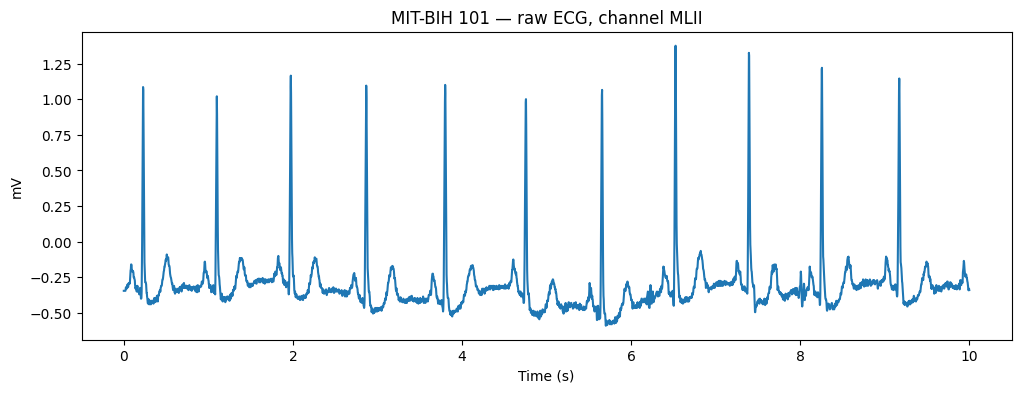

In [4]:
show_s = 10
n = int(show_s * fs)

plt.plot(t[:n], ecg[:n])
plt.xlabel("Time (s)")
plt.ylabel(record.units[0])
plt.title(f"MIT-BIH {record_name} — raw ECG, channel {record.sig_name[0]}")
plt.show()

## `nk.ecg_process()`

NeuroKit2 provides a convenient ECG processing pipeline:

```python
signals, info = nk.ecg_process(
    ecg,
    sampling_rate=fs
)
```

It returns:

- `signals`: sample-level DataFrame;
- `info`: detected event locations and processing information.

In [5]:
signals, info = nk.ecg_process(
    ecg,
    sampling_rate=fs
)

print(signals.shape)
print(type(signals))
print(type(info))

(43200, 19)
<class 'pandas.core.frame.DataFrame'>
<class 'dict'>


## Inspect the output — do not guess

The processed DataFrame contains variables such as:

- raw ECG;
- cleaned ECG;
- interpolated heart rate;
- quality;
- R-peak markers;
- P/Q/S/T-related landmark markers.

The exact columns are easy to inspect.

In [6]:
print(signals.columns.tolist())

signals[["ECG_Raw", "ECG_Clean", "ECG_Rate", "ECG_Quality", "ECG_R_Peaks"]].head()

['ECG_Raw', 'ECG_Clean', 'ECG_Rate', 'ECG_Quality', 'ECG_R_Peaks', 'ECG_P_Peaks', 'ECG_P_Onsets', 'ECG_P_Offsets', 'ECG_Q_Peaks', 'ECG_R_Onsets', 'ECG_R_Offsets', 'ECG_S_Peaks', 'ECG_T_Peaks', 'ECG_T_Onsets', 'ECG_T_Offsets', 'ECG_Phase_Atrial', 'ECG_Phase_Completion_Atrial', 'ECG_Phase_Ventricular', 'ECG_Phase_Completion_Ventricular']


,ECG_Raw,ECG_Clean,ECG_Rate,ECG_Quality,ECG_R_Peaks
0,-0.345,-0.020809,69.981688,0.932656,0
1,-0.345,-0.021020,69.981688,0.932656,0
2,-0.345,-0.020925,69.981688,0.932656,0
3,-0.345,-0.020320,69.981688,0.932656,0
4,-0.345,-0.019204,69.981688,0.932656,0


## Inspect the processed ECG

`nk.ecg_plot()` provides a quick visual check of the processed output.

Use it to inspect:

- cleaning;
- detected beats;
- heart rate;
- quality;
- heartbeat morphology.


We should also compare the **raw and cleaned ECG directly**.

Remember from Lecture 4:

> a cleaner-looking signal is not automatically a more physiologically faithful signal.


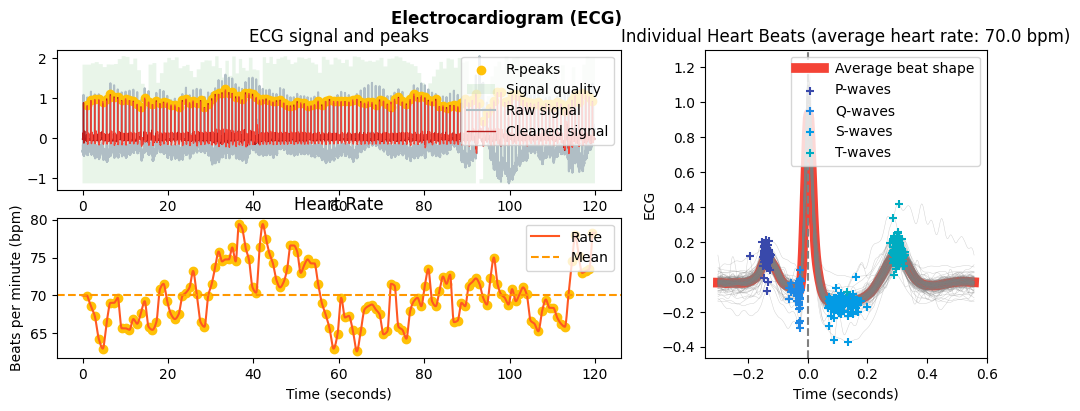

In [7]:
nk.ecg_plot(signals, info)
plt.show()

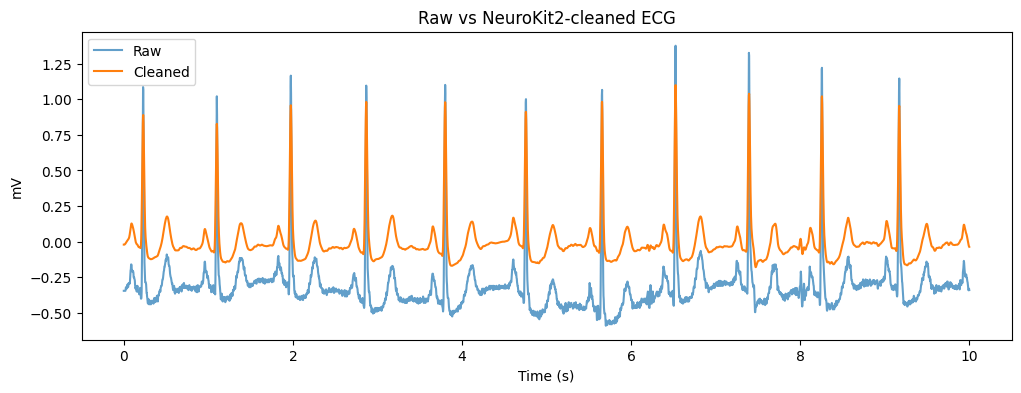

In [8]:
plt.plot(t[:n], signals["ECG_Raw"].iloc[:n], label="Raw", alpha=0.7)
plt.plot(t[:n], signals["ECG_Clean"].iloc[:n], label="Cleaned")
plt.xlabel("Time (s)")
plt.ylabel(record.units[0])
plt.title("Raw vs NeuroKit2-cleaned ECG")
plt.legend()
plt.show()

## R-peaks: the key event for many ECG features

The **R-peak** is the prominent ventricular depolarization landmark in many ECG leads.

Once R-peaks are detected, we can derive:

- beat count;
- RR intervals;
- heart rate;
- beat-to-beat variability;
- heartbeat-centred windows.

NeuroKit2 stores detected R-peak sample indices in:

```python
info["ECG_R_Peaks"]
```

In [9]:
rpeaks = np.asarray(info["ECG_R_Peaks"])

print("Detected R-peaks:", len(rpeaks))
print("First 10 samples:", rpeaks[:10])
print("First 10 times (s):", np.round(rpeaks[:10] / fs, 3))

Detected R-peaks: 139
First 10 samples: [ 396  711 1032 1368 1711 2036 2349 2662 2972 3301]
First 10 times (s): [1.1   1.975 2.867 3.8   4.753 5.656 6.525 7.394 8.256 9.169]


## Overlay detected R-peaks

A detected event should be **visually verified** against the waveform.

This is one of the most important habits in biosignal analysis.

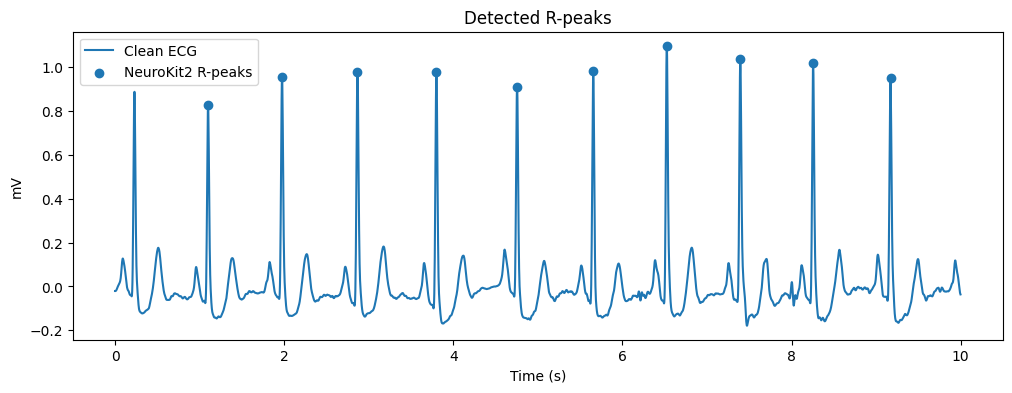

In [10]:
r_show = rpeaks[rpeaks < n]

plt.plot(t[:n], signals["ECG_Clean"].iloc[:n], label="Clean ECG")
plt.scatter(
    r_show / fs,
    signals["ECG_Clean"].to_numpy()[r_show],
    marker="o",
    label="NeuroKit2 R-peaks"
)

plt.xlabel("Time (s)")
plt.ylabel(record.units[0])
plt.title("Detected R-peaks")
plt.legend()
plt.show()

## Compare with PhysioNet reference annotations

MIT-BIH includes expert-reviewed beat annotations.

This gives us something valuable:

**algorithmic detection vs external reference annotations**

The annotation location is associated with the QRS complex and is useful for visual comparison with detected R-peaks.

We will not perform a full detector benchmark today.

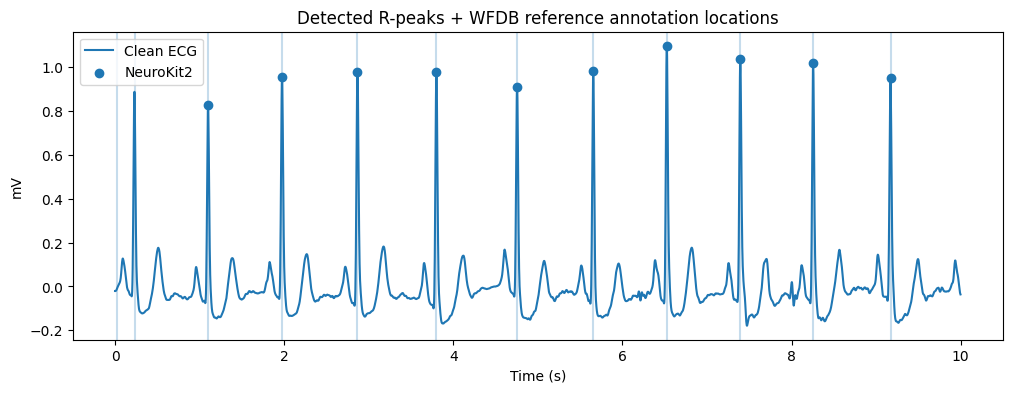

In [11]:
ann = wfdb.rdann(
    record_name,
    "atr",
    pn_dir="mitdb",
    sampfrom=0,
    sampto=int(duration_s * fs)
)

ann_show = ann.sample[ann.sample < n]

plt.plot(t[:n], signals["ECG_Clean"].iloc[:n], label="Clean ECG")

plt.scatter(
    r_show / fs,
    signals["ECG_Clean"].to_numpy()[r_show],
    marker="o",
    label="NeuroKit2"
)

for s in ann_show:
    plt.axvline(s / fs, alpha=0.25)

plt.xlabel("Time (s)")
plt.ylabel(record.units[0])
plt.title("Detected R-peaks + WFDB reference annotation locations")
plt.legend()
plt.show()

## RR intervals

If R-peaks occur at samples:

$r_1, r_2, r_3, ...$

then consecutive RR intervals are:

$RR_i = \frac{r_{i+1} - r_i}{f_s}$

This gives the beat-to-beat interval in **seconds**.

For HRV, RR/NN intervals are often expressed in **milliseconds**.

In [12]:
rr_s = np.diff(rpeaks) / fs
rr_ms = rr_s * 1000

rr_df = pd.DataFrame({
    "time_s": rpeaks[1:] / fs,
    "rr_s": rr_s,
    "rr_ms": rr_ms
})

rr_df.head()

,time_s,rr_s,rr_ms
0,1.975000,0.875000,875.000000
1,2.866667,0.891667,891.666667
2,3.800000,0.933333,933.333333
3,4.752778,0.952778,952.777778
4,5.655556,0.902778,902.777778


## RR interval → instantaneous heart rate

A simple beat-to-beat heart-rate estimate is:

$HR = \frac{60}{RR}$


where RR is measured in seconds.

NeuroKit2 also provides an interpolated sample-level `ECG_Rate` signal.

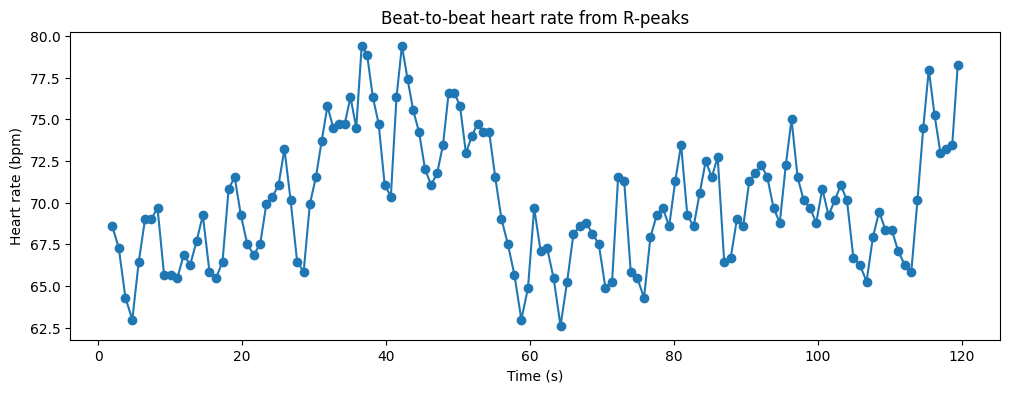

In [13]:
rr_df["heart_rate_bpm"] = 60 / rr_df["rr_s"]

plt.plot(rr_df["time_s"], rr_df["heart_rate_bpm"], "o-")
plt.xlabel("Time (s)")
plt.ylabel("Heart rate (bpm)")
plt.title("Beat-to-beat heart rate from R-peaks")
plt.show()

## A small set of interpretable rate features

From one recording we can already calculate:

- detected beat count;
- mean / median heart rate;
- mean RR interval;
- standard deviation of RR intervals;
- RMSSD;
- mean ECG quality.

This converts thousands of signal samples into a small physiological description.

In [14]:
rmssd_ms = np.sqrt(np.mean(np.diff(rr_ms) ** 2))

simple_features = pd.DataFrame([{
    "record": record_name,
    "duration_s": duration_s,
    "n_beats": len(rpeaks),
    "mean_hr_bpm": rr_df["heart_rate_bpm"].mean(),
    "median_hr_bpm": rr_df["heart_rate_bpm"].median(),
    "mean_rr_ms": rr_ms.mean(),
    "sd_rr_ms": rr_ms.std(ddof=1),
    "rmssd_ms": rmssd_ms,
    "mean_ecg_quality": signals["ECG_Quality"].mean()
}])

simple_features.round(2)

,record,duration_s,n_beats,mean_hr_bpm,median_hr_bpm,mean_rr_ms,sd_rr_ms,rmssd_ms,mean_ecg_quality
0,101,120,139,70.18,69.68,857.37,45.47,28.35,0.9


## ECG quality becomes a feature too

NeuroKit2's `ECG_Quality` is a **relative signal-quality indicator**, not a clinical diagnosis.

Possible uses:

- visualize where quality falls;
- summarize average quality per recording;
- flag windows for inspection;
- include quality as metadata alongside features.

Do not automatically delete data using an arbitrary threshold.

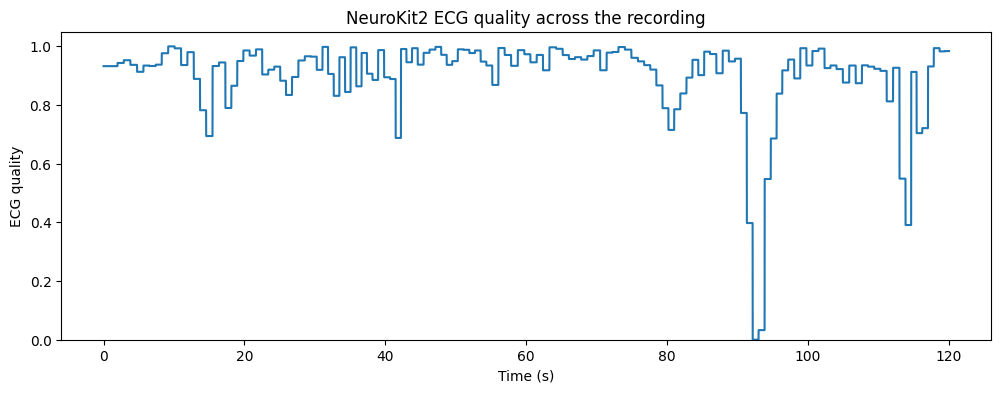

In [15]:
plt.plot(t, signals["ECG_Quality"])
plt.ylim(0, 1.05)
plt.xlabel("Time (s)")
plt.ylabel("ECG quality")
plt.title("NeuroKit2 ECG quality across the recording")
plt.show()

## Segment ECG into individual heartbeats

Lecture 4 introduced fixed and overlapping windows.

For ECG morphology we can instead use **event-based windows** centred on R-peaks.

NeuroKit2 provides:

```python
nk.ecg_segment(...)
```

This aligns beats so their morphology can be compared.

Number of detected R-peaks: 139


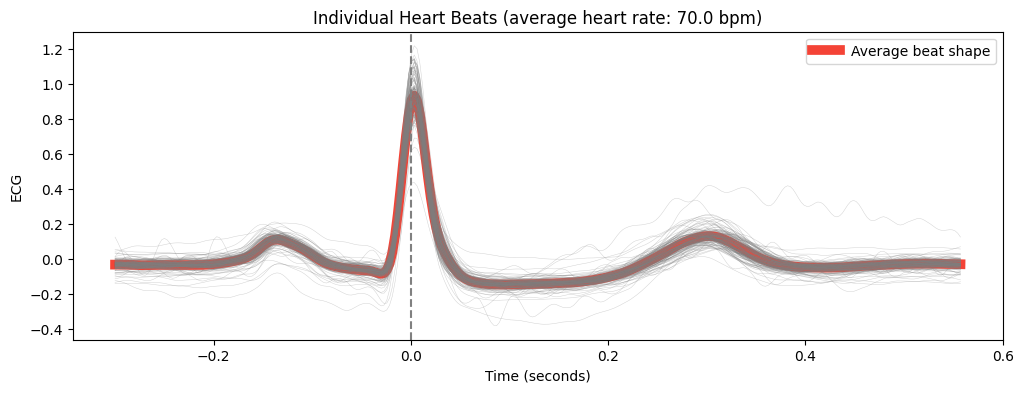

Number of segmented beats: 139


In [17]:
rpeaks = np.asarray(
    info["ECG_R_Peaks"]
)


print(
    "Number of detected R-peaks:",
    len(rpeaks)
)


heartbeats = nk.ecg_segment(
    signals["ECG_Clean"].to_numpy(),
    rpeaks=rpeaks,
    sampling_rate=fs,
    show=True
)


plt.show()


print(
    "Number of segmented beats:",
    len(heartbeats)
)

## A simple morphology feature: R-peak amplitude

Not every feature has to be complicated.

For each detected R-peak, we can read the cleaned ECG amplitude at that sample.

This creates one value per beat.

Later we can summarize those beat-level values per window or recording.

In [18]:
clean_ecg = signals["ECG_Clean"].to_numpy()
r_amplitude = clean_ecg[rpeaks]

beat_features = pd.DataFrame({
    "rpeak_sample": rpeaks,
    "time_s": rpeaks / fs,
    "r_amplitude": r_amplitude
})

beat_features.head()

,rpeak_sample,time_s,r_amplitude
0,396,1.100000,0.826496
1,711,1.975000,0.956927
2,1032,2.866667,0.980729
3,1368,3.800000,0.978501
4,1711,4.752778,0.910556


## ECG landmarks and morphology features

A cardiac cycle contains approximately:

**P wave → QRS complex → T wave**

NeuroKit2 can identify markers such as:

- P peaks;
- Q and S peaks;
- T peaks;
- R onset / offset;
- P and T onset / offset.


Once landmarks are trustworthy, examples of morphology-related features include:

- PR interval;
- QRS duration;
- QT interval;
- P/R/T amplitudes;
- beat-to-beat morphology variation.

But there is an important dependency:

> **bad landmark detection → bad physiological features**

For this introductory course, we focus mainly on robust rate- and interval-based features rather than building a full ECG morphology pipeline.


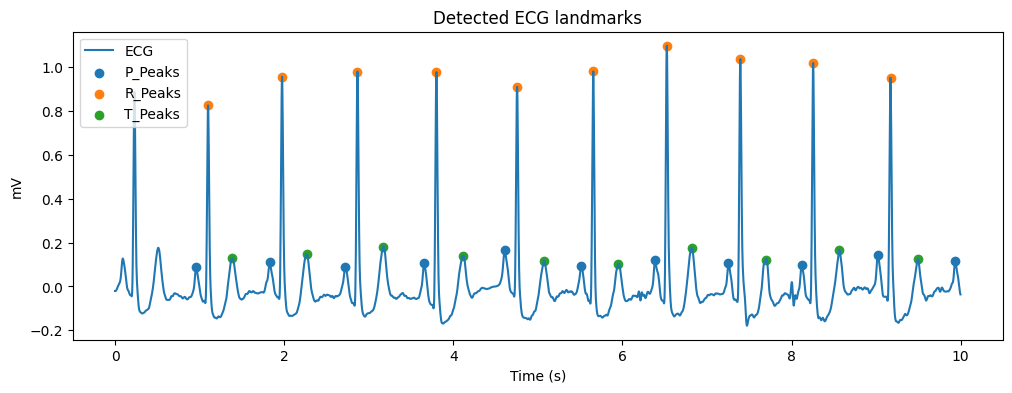

In [19]:
marker_cols = [
    "ECG_P_Peaks",
    "ECG_R_Peaks",
    "ECG_T_Peaks"
]

plt.plot(t[:n], signals["ECG_Clean"].iloc[:n], label="ECG")

for col in marker_cols:
    idx = np.where(signals[col].to_numpy()[:n] == 1)[0]
    plt.scatter(
        idx / fs,
        signals["ECG_Clean"].to_numpy()[idx],
        label=col.replace("ECG_", "")
    )

plt.xlabel("Time (s)")
plt.ylabel(record.units[0])
plt.title("Detected ECG landmarks")
plt.legend()
plt.show()

## Heart-rate variability: the basic idea

Heartbeats are not perfectly periodic.

**Heart-rate variability (HRV)** describes variation in consecutive beat intervals.

Three introductory time-domain quantities:

### MeanNN
mean normal-to-normal interval

### SDNN
standard deviation of NN intervals

### RMSSD
root mean square of successive interval differences


NeuroKit2 provides:

```python
nk.hrv_time(...)
```

It returns many metrics.

For this course we select only a few interpretable ones rather than using every available column.


In [20]:
hrv = nk.hrv_time(
    rpeaks,
    sampling_rate=fs,
    show=False
)

selected_hrv = [
    c for c in
    ["HRV_MeanNN", "HRV_SDNN", "HRV_RMSSD", "HRV_pNN50"]
    if c in hrv.columns
]

hrv[selected_hrv].round(2)

,HRV_MeanNN,HRV_SDNN,HRV_RMSSD,HRV_pNN50
0,857.37,45.47,28.35,7.97


## HRV needs enough good data

Do **not** assume:

> “NeuroKit2 returned a number, therefore the number is reliable.”

HRV estimates depend on:

- recording duration;
- correct beat detection;
- ectopic / abnormal beats;
- artefacts;
- missing intervals;
- physiological state.

Our 120-second example is mainly for learning the workflow.

Some HRV measures explicitly require several minutes of data.

## Combine features into one record-level row

This is the format we eventually want for modelling:

| record | mean HR | MeanNN | SDNN | RMSSD | quality | R amplitude |
|---|---:|---:|---:|---:|---:|---:|

One row can represent:

- a full record;
- one participant;
- one visit;
- one analysis window.

The **unit of analysis** must be explicit.

In [21]:
feature_row = {
    "record": record_name,
    "duration_s": duration_s,
    "n_beats": len(rpeaks),
    "mean_hr_bpm": rr_df["heart_rate_bpm"].mean(),
    "mean_ecg_quality": signals["ECG_Quality"].mean(),
    "mean_r_amplitude": np.mean(r_amplitude)
}

for col in selected_hrv:
    feature_row[col] = hrv.loc[0, col]

record_features = pd.DataFrame([feature_row])
record_features.round(2)

,record,duration_s,n_beats,mean_hr_bpm,mean_ecg_quality,mean_r_amplitude,HRV_MeanNN,HRV_SDNN,HRV_RMSSD,HRV_pNN50
0,101,120,139,70.18,0.9,0.93,857.37,45.47,28.35,7.97


## Automated feature extraction: useful, but inspect the output

For longer ECG periods:

```python
nk.ecg_analyze(...)
```

can create a large feature table automatically.

Useful?

**Yes — but inspect what it produces.**

More columns do not automatically mean more information.


For a small health-data-science project, start with features that you can explain.

### Better first feature set

- mean HR;
- RR / pulse interval;
- SDNN / RMSSD when appropriate;
- signal quality;
- meaningful morphology features.

### Avoid

- collecting 100 variables simply because a library returns them;
- using features without knowing their units;
- extracting HRV from very short/noisy segments;
- mixing participant-level and window-level rows.

Next week, `tsfresh` will intentionally explore **large-scale automatic feature extraction**.


In [22]:
all_features = nk.ecg_analyze(
    signals,
    sampling_rate=fs,
    method="interval-related"
)

print("Feature table shape:", all_features.shape)
print("First 15 columns:")
print(all_features.columns[:15].tolist())

Feature table shape: (1, 96)
First 15 columns:
['ECG_Rate_Mean', 'HRV_MeanNN', 'HRV_SDNN', 'HRV_SDANN1', 'HRV_SDNNI1', 'HRV_SDANN2', 'HRV_SDNNI2', 'HRV_SDANN5', 'HRV_SDNNI5', 'HRV_RMSSD', 'HRV_SDSD', 'HRV_CVNN', 'HRV_CVSD', 'HRV_MedianNN', 'HRV_MadNN']


## PPG feature extraction with real PhysioNet data

Photoplethysmography (PPG / `PLETH`) measures pulsatile blood-volume changes.

A typical PPG pipeline is:

**raw PPG → cleaning → systolic peak detection → pulse intervals → pulse rate**

NeuroKit2 provides:

```python
nk.ppg_process(...)
```


We reuse the **Challenge 2015** waveform example from earlier lectures.

Record: `a103l`

Now we are no longer only plotting the channels — we will extract physiological variables from them.

The physiology differs from ECG, even though both signals can estimate cardiac rate.


In [23]:
multi_name = "a103l"
multi_dir = "challenge-2015/training"
multi_duration_s = 60

multi_header = wfdb.rdheader(multi_name, pn_dir=multi_dir)
fs_multi = multi_header.fs

multi = wfdb.rdrecord(
    multi_name,
    pn_dir=multi_dir,
    sampfrom=0,
    sampto=int(multi_duration_s * fs_multi)
)

print("Sampling frequency:", fs_multi)
print("Channels:", multi.sig_name)
print("Units:", multi.units)

Sampling frequency: 250
Channels: ['II', 'V', 'PLETH']
Units: ['mV', 'mV', 'NU']


## Select and process the PLETH channel

We first locate the channel by name rather than assuming a fixed column index.

Then NeuroKit2 gives us:

- raw PPG;
- cleaned PPG;
- PPG-derived rate;
- detected pulse peaks.

PLETH channel: PLETH
['PPG_Raw', 'PPG_Clean', 'PPG_Rate', 'PPG_Quality', 'PPG_Peaks']


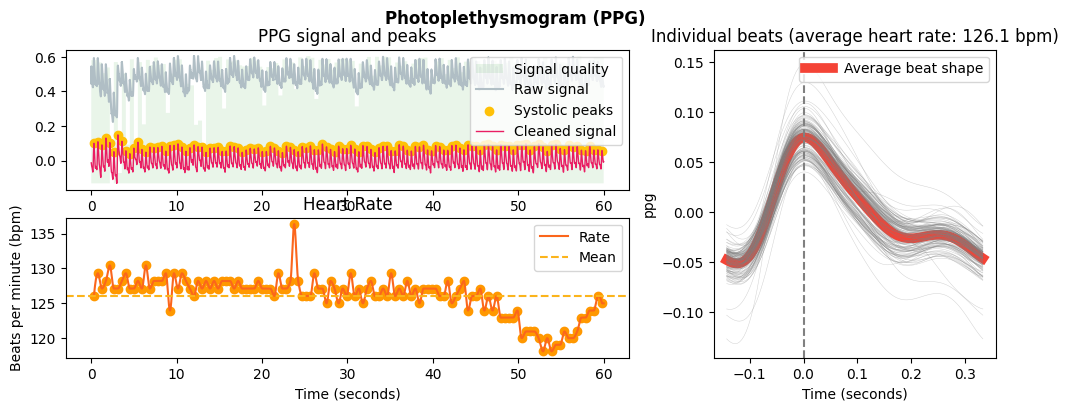

In [24]:
pleth_idx = next(
    i for i, name in enumerate(multi.sig_name)
    if "PLETH" in name.upper()
)

pleth = multi.p_signal[:, pleth_idx]

ppg_signals, ppg_info = nk.ppg_process(
    pleth,
    sampling_rate=fs_multi
)

print("PLETH channel:", multi.sig_name[pleth_idx])
print(ppg_signals.columns.tolist())

nk.ppg_plot(ppg_signals, ppg_info)
plt.show()

## Compare ECG-derived and PPG-derived rate

ECG and PPG are related, but they are **not the same signal**.

Differences can arise from:

- different physiological measurement mechanisms;
- pulse transit;
- noise / motion;
- peak-detection errors;
- missing or poor-quality segments.

Agreement is useful — disagreement is also informative.

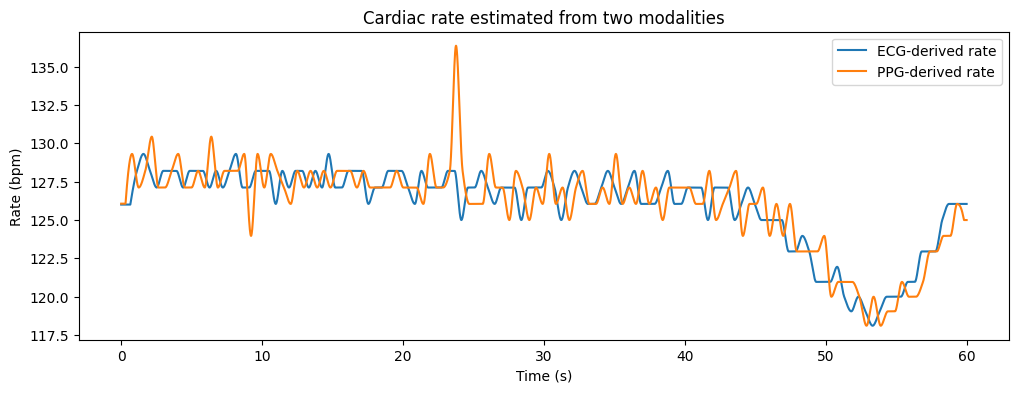

In [25]:
ecg_candidates = [
    i for i, name in enumerate(multi.sig_name)
    if name.upper() in {"I", "II", "III", "V", "V1", "V2", "ECG", "MLII"}
    or "ECG" in name.upper()
]

ecg_idx = ecg_candidates[0]
ecg_multi = multi.p_signal[:, ecg_idx]

ecg_multi_signals, ecg_multi_info = nk.ecg_process(
    ecg_multi,
    sampling_rate=fs_multi
)

tm = np.arange(multi.sig_len) / fs_multi

plt.plot(tm, ecg_multi_signals["ECG_Rate"], label="ECG-derived rate")
plt.plot(tm, ppg_signals["PPG_Rate"], label="PPG-derived rate")
plt.xlabel("Time (s)")
plt.ylabel("Rate (bpm)")
plt.title("Cardiac rate estimated from two modalities")
plt.legend()
plt.show()

## A small multimodal feature row

We can summarize both modalities in the **same record-level table**.

This is the bridge toward later multimodal analysis.

Important:

- features must refer to the same recording interval;
- units must be compatible;
- missing modalities must be handled explicitly.

In [26]:
multi_features = pd.DataFrame([{
    "record": multi_name,
    "duration_s": multi_duration_s,
    "ecg_mean_rate_bpm": np.nanmean(ecg_multi_signals["ECG_Rate"]),
    "ecg_rate_sd_bpm": np.nanstd(ecg_multi_signals["ECG_Rate"], ddof=1),
    "ecg_detected_beats": len(ecg_multi_info["ECG_R_Peaks"]),
    "ppg_mean_rate_bpm": np.nanmean(ppg_signals["PPG_Rate"]),
    "ppg_rate_sd_bpm": np.nanstd(ppg_signals["PPG_Rate"], ddof=1),
    "ppg_detected_pulses": len(ppg_info["PPG_Peaks"])
}])

multi_features.round(2)

,record,duration_s,ecg_mean_rate_bpm,ecg_rate_sd_bpm,ecg_detected_beats,ppg_mean_rate_bpm,ppg_rate_sd_bpm,ppg_detected_pulses
0,a103l,60,126.01,2.59,125,126.08,2.78,126


## EEG: from waveform to frequency-band features

EEG contains much faster and more complex activity than ECG or PPG.

A common way to summarize EEG is by measuring signal power in frequency bands such as:

- **Delta:** 1–4 Hz
- **Theta:** 4–8 Hz
- **Alpha:** 8–13 Hz
- **Beta:** 13–30 Hz

For this example we use the NeuroKit2 example EEG signal:

```python
nk.data("eeg_150hz")
```

The purpose is to understand the **feature-extraction workflow**, not to interpret brain state clinically.


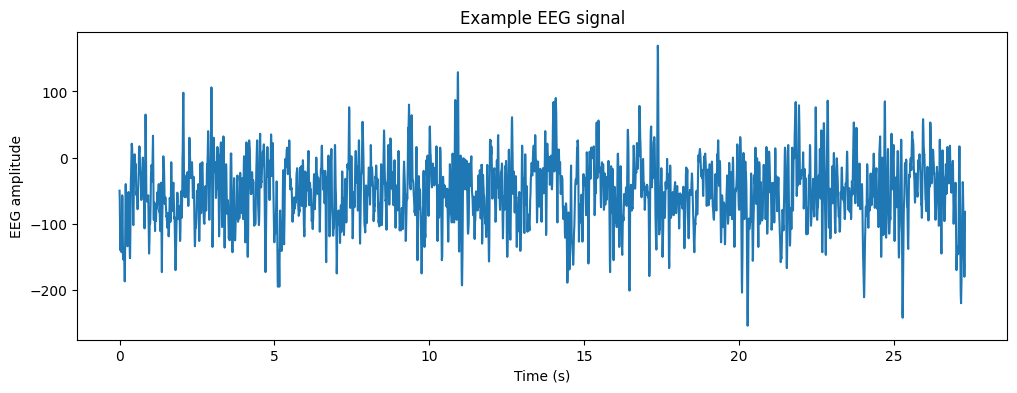

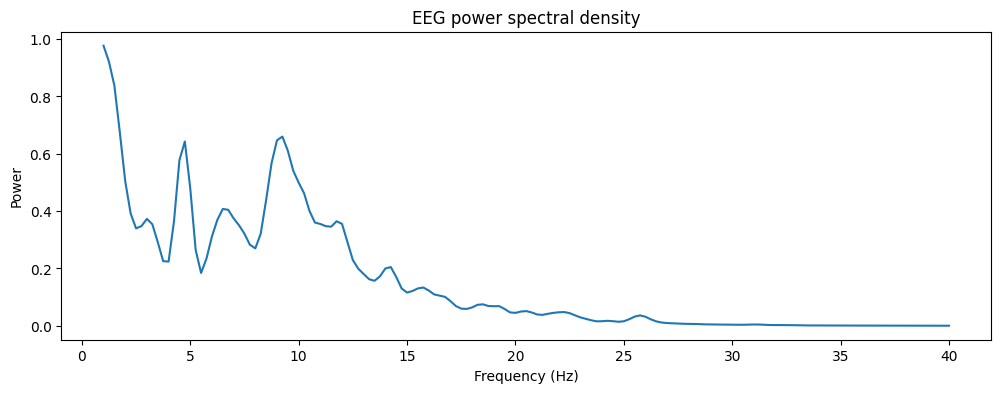

In [27]:
eeg = nk.data("eeg_150hz")
eeg_fs = 150

eeg_duration_s = 30
eeg_segment = eeg[:int(eeg_duration_s * eeg_fs)]

t_eeg = np.arange(len(eeg_segment)) / eeg_fs

plt.plot(t_eeg, eeg_segment)
plt.xlabel("Time (s)")
plt.ylabel("EEG amplitude")
plt.title("Example EEG signal")
plt.show()


eeg_psd = nk.signal_psd(
    eeg_segment,
    sampling_rate=eeg_fs,
    min_frequency=1,
    max_frequency=40
)

plt.plot(eeg_psd["Frequency"], eeg_psd["Power"])
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power")
plt.title("EEG power spectral density")
plt.show()


## EEG frequency-band feature table

Instead of using all EEG samples directly, we can summarize the signal using band powers.

These features are different from ECG features:

```text
ECG → detected physiological events → RR / HRV features

EEG → distribution of signal power across frequencies
```

The band definitions are approximate and should always be documented.


In [28]:
eeg_power = nk.eeg_power(
    eeg_segment[np.newaxis, :],
    sampling_rate=eeg_fs,
    frequency_band=[
        "Delta",
        "Theta",
        "Alpha",
        "Beta"
    ]
)

eeg_power


,Channel,Delta,Theta,Alpha,Beta
0,EEG_0,0.548071,0.475916,0.708807,0.364679


In [29]:
eeg_features = pd.DataFrame([{
    "duration_s": eeg_duration_s,

    "eeg_mean": np.mean(eeg_segment),
    "eeg_std": np.std(eeg_segment),

    "delta_power": eeg_power.loc[0, "Delta"],
    "theta_power": eeg_power.loc[0, "Theta"],
    "alpha_power": eeg_power.loc[0, "Alpha"],
    "beta_power": eeg_power.loc[0, "Beta"]
}])

eeg_features.round(4)


,duration_s,eeg_mean,eeg_std,delta_power,theta_power,alpha_power,beta_power
0,30,-52.4438,48.8186,0.5481,0.4759,0.7088,0.3647


## Accelerometry: movement from three axes

Wearable accelerometers commonly measure movement along three axes:

```text
X
Y
Z
```

A simple orientation-independent summary is the acceleration magnitude:

$m = \sqrt{x^2 + y^2 + z^2}$

For the same PhysioNet exam session, the Empatica E4 accelerometer is sampled at **32 Hz**.

Unlike ECG or EDA, we do not need a special peak detector to create useful introductory movement features.


ACC sampling frequency: 32 Hz
ACC duration: 60.0 s


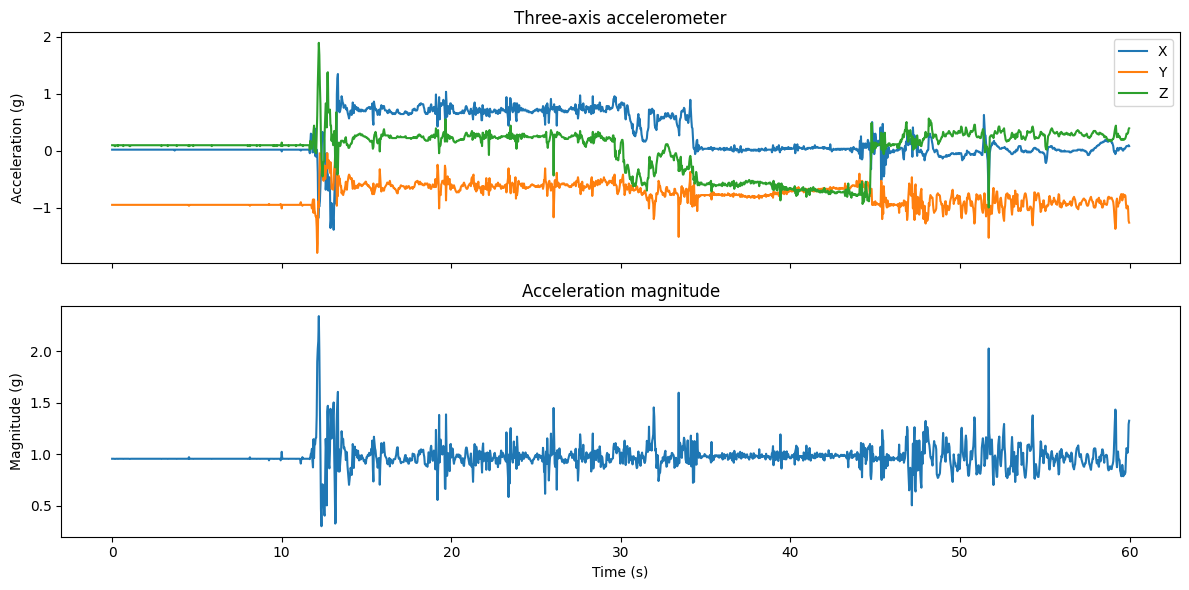

In [33]:
acc_url = f"{wearable_base}/ACC.csv"


acc_header = pd.read_csv(
    acc_url,
    header=None,
    nrows=2
)

acc_fs = int(acc_header.iloc[1, 0])


acc_duration_s = 60

acc_raw = pd.read_csv(
    acc_url,
    header=None,
    skiprows=2,
    nrows=int(acc_duration_s * acc_fs)
)

acc = acc_raw.iloc[:, :3].astype(float).copy()
acc.columns = ["X", "Y", "Z"]


# Empatica E4 acceleration is stored in units of 1/64 g

acc[["X", "Y", "Z"]] = (
    acc[["X", "Y", "Z"]] / 64.0
)

acc["Magnitude"] = np.sqrt(
    acc["X"]**2
    + acc["Y"]**2
    + acc["Z"]**2
)

t_acc = np.arange(len(acc)) / acc_fs

print("ACC sampling frequency:", acc_fs, "Hz")
print("ACC duration:", len(acc) / acc_fs, "s")


fig, axes = plt.subplots(
    2,
    1,
    figsize=(12, 6),
    sharex=True
)

axes[0].plot(t_acc, acc["X"], label="X")
axes[0].plot(t_acc, acc["Y"], label="Y")
axes[0].plot(t_acc, acc["Z"], label="Z")

axes[0].set_ylabel("Acceleration (g)")
axes[0].set_title("Three-axis accelerometer")
axes[0].legend()


axes[1].plot(
    t_acc,
    acc["Magnitude"]
)

axes[1].set_xlabel("Time (s)")
axes[1].set_ylabel("Magnitude (g)")
axes[1].set_title("Acceleration magnitude")

plt.tight_layout()
plt.show()


## Simple accelerometry features

For a fixed activity window we can calculate interpretable summaries such as:

- mean acceleration magnitude;
- standard deviation of magnitude;
- maximum magnitude;
- mean absolute change in magnitude.

These features describe **how much the sensor moved**, not why it moved.

Later, window-level features like these can be combined with ECG, PPG, EDA, or clinical variables.


In [34]:
magnitude = acc["Magnitude"].to_numpy()

acc_features = pd.DataFrame([{
    "duration_s": acc_duration_s,

    "mean_magnitude_g": np.mean(magnitude),
    "sd_magnitude_g": np.std(magnitude, ddof=1),
    "max_magnitude_g": np.max(magnitude),

    "mean_absolute_change_g": np.mean(
        np.abs(np.diff(magnitude))
    )
}])

acc_features.round(4)


,duration_s,mean_magnitude_g,sd_magnitude_g,max_magnitude_g,mean_absolute_change_g
0,60,0.9771,0.1211,2.3416,0.0541


## Exercise 1 — ECG feature extraction (30 min)

Use **MIT-BIH record `100`**, channel 0, first **90 seconds**.

### Tasks

1. load and plot the first 10 s;
2. run `nk.ecg_process()`;
3. overlay detected R-peaks;
4. calculate RR intervals;
5. create a one-row table containing:
   - detected beat count;
   - mean HR;
   - mean RR;
   - SDNN;
   - RMSSD;
   - mean ECG quality;
6. write **three observations** about the signal and features.

### Starter code
Complete the `TODO`s below.

In [ ]:
exercise_record = "100"
exercise_duration_s = 90

hdr_ex = wfdb.rdheader(exercise_record, pn_dir="mitdb")
fs_ex = hdr_ex.fs

rec_ex = wfdb.rdrecord(
    exercise_record,
    pn_dir="mitdb",
    sampfrom=0,
    sampto=int(exercise_duration_s * fs_ex)
)

ecg_ex = rec_ex.p_signal[:, 0]

# TODO 1: create a time axis and plot the first 10 s

In [ ]:
# TODO 2: process the ECG
# ex_signals, ex_info = nk.ecg_process(...)

# TODO 3: extract detected R-peaks
# ex_rpeaks = ...

# TODO 4: overlay the R-peaks on the cleaned ECG

In [ ]:
# TODO 5: calculate RR intervals in seconds and milliseconds
# ex_rr_s = ...
# ex_rr_ms = ...

# TODO 6: calculate:
# - n_beats
# - mean_hr_bpm
# - mean_rr_ms
# - sdnn_ms
# - rmssd_ms
# - mean_quality

# TODO 7: create a one-row pandas DataFrame called ex_features
# ex_features

## Exercise 2 — PPG + project checkpoint (30 min)

### Part A — Real PPG

Use Challenge 2015 record `a103l`.

1. load 60 s;
2. locate `PLETH`;
3. process it using `nk.ppg_process()`;
4. plot the processed PPG;
5. extract:
   - pulse count;
   - mean pulse rate;
   - pulse-rate SD.

### Part B — Your semester project

For your chosen dataset, decide:

- **what is one row in your future feature table?**
- which channel(s) will you use?
- which 3–6 physiological features are meaningful?
- what preprocessing must happen first?
- if you use EEG, EDA, or accelerometry, which modality-specific features would you extract?

Add a small feature-extraction prototype to your project notebook/repository.

**Suggested commit:** `Add physiological feature extraction`

In [ ]:
# Part A starter code

project_record = "a103l"
project_dir = "challenge-2015/training"
project_duration_s = 60

hdr_p = wfdb.rdheader(project_record, pn_dir=project_dir)
fs_p = hdr_p.fs

rec_p = wfdb.rdrecord(
    project_record,
    pn_dir=project_dir,
    sampfrom=0,
    sampto=int(project_duration_s * fs_p)
)

print(rec_p.sig_name)

# TODO 1: find the PLETH channel index
pleth_idx_p = None

# TODO 2: extract the PLETH signal
pleth_p = None

# TODO 3: run nk.ppg_process(...)
# ppg_p, info_p = ...

# TODO 4: plot with nk.ppg_plot(...)

In [ ]:
# TODO 5: create one feature row

# ppg_feature_row = pd.DataFrame([{
#     "record": project_record,
#     "pulse_count": ...,
#     "mean_pulse_rate_bpm": ...,
#     "pulse_rate_sd_bpm": ...
# }])

# ppg_feature_row

In [ ]:
# Part B — project checkpoint template

project_plan = pd.DataFrame({
    "item": [
        "Unit of analysis",
        "Signal/channel",
        "Preprocessing",
        "Feature 1",
        "Feature 2",
        "Feature 3",
        "Quality check"
    ],
    "your_plan": [
        "",
        "",
        "",
        "",
        "",
        "",
        ""
    ]
})

project_plan

## Take-home checklist

Before trusting physiological features, ask:

- **Was the raw signal inspected?**
- **Was preprocessing appropriate for this signal?**
- **Were physiological events detected correctly?**
- **Do the features have meaningful units?**
- **Is the recording long enough for the feature?**
- **Does signal quality affect the estimate?**
- **What does one row of the feature table represent?**
- **Can another person reproduce the feature extraction?**

### Today
**biosignal → physiological event → interpretable features**


# Thank you!